In [1]:
# Step 1: Upload the ticket CSV and inspect it
import pandas as pd
from google.colab import files

# Opens a file picker; choose the ticket CSV file
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

Saving all_tickets_processed_improved_v3.csv to all_tickets_processed_improved_v3.csv


In [2]:
df = pd.read_csv(file_name, encoding="latin-1")

print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types and missing values:")
df.info()
print("\nFirst 5 rows:")
print(df.head())

# Duplicates and missing values
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing values per column:")
print(df.isnull().sum())

# Auto-detect likely label columns: text columns with few unique values
print("\nLikely label columns (few unique values):")
for col in df.select_dtypes(include="object").columns:
    n_unique = df[col].nunique()
    if n_unique <= 30:
        print(f"\n--- {col} ({n_unique} classes) ---")
        print(df[col].value_counts())

Shape (rows, columns): (47837, 2)

Columns: ['Document', 'Topic_group']

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     47837 non-null  object
 1   Topic_group  47837 non-null  object
dtypes: object(2)
memory usage: 747.6+ KB

First 5 rows:
                                            Document    Topic_group
0  connection with icon icon dear please setup ic...       Hardware
1  work experience user work experience user hi w...         Access
2  requesting for meeting requesting meeting hi p...       Hardware
3  reset passwords for external accounts re expir...         Access
4  mail verification warning hi has got attached ...  Miscellaneous

Duplicate rows: 0

Missing values per column:
Document       0
Topic_group    0
dtype: int64

Likely label columns (few unique values):

--- Topic_group (8 cl

In [3]:
text_cols = df.select_dtypes(include="object").columns
avg_len = {c: df[c].astype(str).str.len().mean() for c in text_cols}
print("\nAverage text length per column (the text column is usually the longest):")
for c, l in sorted(avg_len.items(), key=lambda x: -x[1]):
    print(f"  {c}: {l:.0f} characters")

# Show 3 sample tickets from the longest-text column
longest = max(avg_len, key=avg_len.get)
print(f"\nSample values from '{longest}':")
for t in df[longest].dropna().sample(3, random_state=42):
    print("-", str(t)[:300])



Average text length per column (the text column is usually the longest):
  Document: 292 characters
  Topic_group: 10 characters

Sample values from 'Document':
- issue with server process sent tuesday issue with server process hi could you please help with following issue getting once few minutes discipline lead
- new purchase po wednesday february purchase po dear purchased please log installation please take consideration mandatory receipts section order receive item ordered kind regards administrator information
- oracle pas urgent re we updated rights query hi can get some assistance here looks like have full control for codes only one working for cannot forecast need done by friday thanks programme portfolio officer mobile phone


In [4]:
import re
import nltk
import matplotlib.pyplot as plt
from collections import Counter
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

# Safety check: Step 1 must have created 'df'
assert "df" in globals(), "Run Step 1 first (the 'df' table is missing)."

In [5]:
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

# ---------- 1) Set up cleaning tools ----------
tokenizer = RegexpTokenizer(r"[a-z]+")   # keeps only runs of letters
lemmatizer = WordNetLemmatizer()         # reduces words to base form

# Standard English stopwords + noise words seen in the ticket samples
stop_words = set(stopwords.words("english"))
noise_words = {
    "hi", "hello", "dear", "please", "thanks", "thank", "regards", "kind",
    "best", "re", "fw", "fwd", "sir", "madam", "team", "could", "would",
    "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday",
    "january", "february", "march", "april", "may", "june", "july", "august",
    "september", "october", "november", "december",
}
stop_words |= noise_words


Tickets empty after cleaning: 2
Tickets remaining: 47835

Before vs after cleaning (3 examples):

Category: HR Support
RAW  : remove colleagues colleagues good morning please colleagues please add thanks accounts receivable lead planned annual leave november december
CLEAN: remove colleague colleague good morning colleague add account receivable lead planned annual leave

Category: Miscellaneous
RAW  : mailing lists mailing lists addition added added application senior developer tuesday pm mailing lists hi please add these mailing lists application thank br senior developer
CLEAN: mailing list mailing list addition added added application senior developer pm mailing list add mailing list application br senior developer

Category: Access
RAW  : user user hello assign opportunities head architecture cannot him interface please his user configured thank
CLEAN: user user assign opportunity head architecture cannot interface user configured

Average words per ticket after cleaning: 31.0
Sho

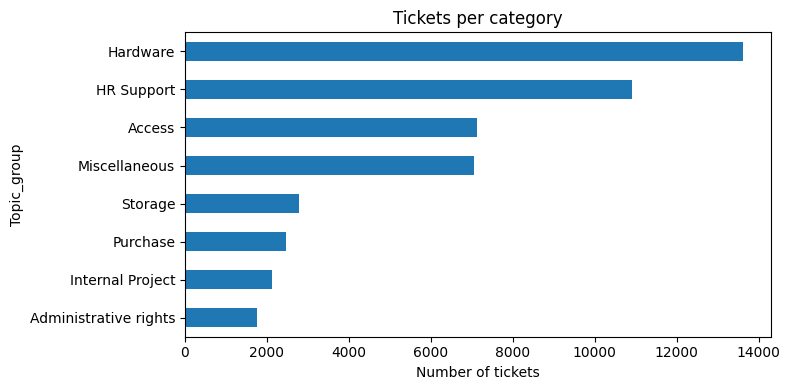

In [6]:
def clean_text(text):
    text = str(text).lower()                           # lowercase
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # remove URLs
    text = re.sub(r"\S+@\S+", " ", text)               # remove email addresses
    tokens = tokenizer.tokenize(text)                  # split into word tokens
    tokens = [t for t in tokens if t not in stop_words and len(t) >= 2]  # drop stopwords/noise
    tokens = [lemmatizer.lemmatize(t) for t in tokens] # base form of each word
    return " ".join(tokens)

# ---------- 3) Apply to the whole dataset (can take about 1 minute) ----------
df["clean_text"] = df["Document"].apply(clean_text)

# Remove tickets that became empty after cleaning
empty = (df["clean_text"].str.strip() == "").sum()
print("Tickets empty after cleaning:", empty)
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)
print("Tickets remaining:", len(df))

# ---------- 4) Before / after examples ----------
print("\nBefore vs after cleaning (3 examples):")
for i in df.sample(3, random_state=1).index:
    print("\nCategory:", df.loc[i, "Topic_group"])
    print("RAW  :", df.loc[i, "Document"][:200])
    print("CLEAN:", df.loc[i, "clean_text"][:200])

# ---------- 5) Text length before vs after ----------
df["word_count"] = df["clean_text"].str.split().str.len()
print("\nAverage words per ticket after cleaning:", round(df["word_count"].mean(), 1))
print("Shortest / longest ticket (words):", df["word_count"].min(), "/", df["word_count"].max())

# ---------- 6) Top words per category (does the text separate the classes?) ----------
print("\nTop 8 words per category:")
for cat, group in df.groupby("Topic_group"):
    words = Counter(" ".join(group["clean_text"]).split())
    print(f"{cat:22s}", [w for w, _ in words.most_common(8)])

# ---------- 7) Data quality check: same text with different labels ----------
dup_text = df.groupby("clean_text")["Topic_group"].nunique()
print("\nCleaned texts that appear with more than one category:", (dup_text > 1).sum())
print("Duplicate cleaned texts overall:", df.duplicated(subset="clean_text").sum())

# ---------- 8) Class balance chart ----------
df["Topic_group"].value_counts().plot(kind="barh", figsize=(8, 4), title="Tickets per category")
plt.xlabel("Number of tickets")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# Safety check: Step 2 must have created 'clean_text'
assert "clean_text" in df.columns, "Run Step 2 first ('clean_text' is missing)."

In [8]:
# ---------- 1) Remove ambiguous and duplicate tickets (prevents train/test leakage) ----------
n_before = len(df)
labels_per_text = df.groupby("clean_text")["Topic_group"].nunique()
conflicting = labels_per_text[labels_per_text > 1].index      # same text, different labels
df_model = df[~df["clean_text"].isin(conflicting)]            # drop ambiguous tickets
df_model = df_model.drop_duplicates(subset="clean_text").reset_index(drop=True)  # keep 1 copy
print(f"Tickets before: {n_before} | after removing duplicates/conflicts: {len(df_model)}")

# ---------- 2) Stratified 80/20 train/test split (keeps class proportions) ----------
X_text = df_model["clean_text"]
y = df_model["Topic_group"]
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, stratify=y, random_state=42
)
print("Train size:", len(X_train_text), "| Test size:", len(X_test_text))

# ---------- 3) TF-IDF features (fit on TRAIN only) ----------
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),   # single words and 2-word phrases
    min_df=3,             # ignore very rare terms
    max_df=0.9,           # ignore terms in over 90% of tickets
    sublinear_tf=True,    # dampen very frequent repeated words
    max_features=100000,
)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
print("TF-IDF matrix shape (train):", X_train.shape)

# ---------- 4) Logistic Regression; 'balanced' helps the small classes ----------
model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

# ---------- 5) Overall metrics ----------
acc = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average="macro")  # treats every class equally
print(f"\nAccuracy: {acc:.3f} | Macro F1: {macro_f1:.3f}")

# ---------- 6) Per-class precision / recall / F1 ----------
print("\nPer-class performance:")
print(classification_report(y_test, pred, digits=3))

Tickets before: 47835 | after removing duplicates/conflicts: 46905
Train size: 37524 | Test size: 9381
TF-IDF matrix shape (train): (37524, 67848)

Accuracy: 0.845 | Macro F1: 0.847

Per-class performance:
                       precision    recall  f1-score   support

               Access      0.896     0.870     0.883      1409
Administrative rights      0.692     0.840     0.759       350
           HR Support      0.878     0.813     0.844      2115
             Hardware      0.854     0.816     0.834      2695
     Internal Project      0.791     0.910     0.846       420
        Miscellaneous      0.784     0.850     0.816      1395
             Purchase      0.930     0.918     0.924       450
              Storage      0.823     0.927     0.872       547

             accuracy                          0.845      9381
            macro avg      0.831     0.868     0.847      9381
         weighted avg      0.848     0.845     0.845      9381



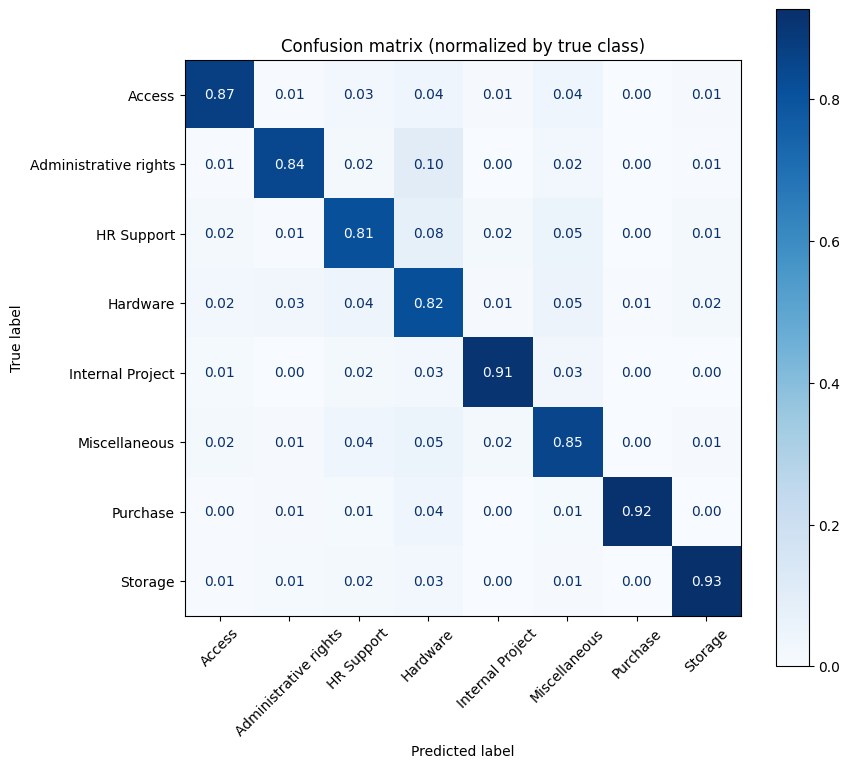

Top 5 confusions (true -> predicted : count):
  HR Support -> Hardware : 164
  Hardware -> Miscellaneous : 139
  Hardware -> HR Support : 120
  HR Support -> Miscellaneous : 102
  Hardware -> Administrative rights : 87

Top 8 words/phrases per category:
Access                 ['confluence', 'user', 'account', 'card', 'license', 'password', 'repository', 'git']
Administrative rights  ['outlook', 'upgrade', 'issue', 'install', 'window', 'software', 'problem', 'version']
HR Support             ['access', 'error', 'oracle', 'leave', 'starter', 'leaver', 'submit', 'time']
Hardware               ['laptop', 'monitor', 'room', 'phone', 'call', 'connection', 'cable', 'sent']
Internal Project       ['code', 'project', 'pipeline', 'setup', 'pa', 'opportunity', 'import', 'unknown']
Miscellaneous          ['change', 'approval', 'add', 'ticket', 'approve', 'group', 'owner', 'approver']
Purchase               ['po', 'purchase', 'installation', 'administrator', 'device', 'log', 'item', 'allocation']
S

In [9]:
# ---------- 7) Confusion matrix (rows = true class, shown as % of that class) ----------
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, normalize="true", xticks_rotation=45,
    values_format=".2f", cmap="Blues", ax=ax,
)
ax.set_title("Confusion matrix (normalized by true class)")
plt.tight_layout()
plt.show()

# ---------- 8) Most-confused category pairs ----------
classes = model.classes_
cm = confusion_matrix(y_test, pred, labels=classes)
pairs = [(classes[i], classes[j], cm[i, j])
         for i in range(len(classes)) for j in range(len(classes)) if i != j]
pairs = sorted(pairs, key=lambda x: -x[2])[:5]
print("Top 5 confusions (true -> predicted : count):")
for t, p, c in pairs:
    print(f"  {t} -> {p} : {c}")

# ---------- 9) Which words drive each category? (explainability) ----------
feature_names = np.array(tfidf.get_feature_names_out())
print("\nTop 8 words/phrases per category:")
for i, cls in enumerate(classes):
    top = np.argsort(model.coef_[i])[-8:][::-1]
    print(f"{cls:22s}", list(feature_names[top]))

# ---------- 10) A few misclassified examples ----------
wrong = np.where(pred != y_test.values)[0][:5]
print("\nSample misclassified tickets:")
for k in wrong:
    print(f"\nTRUE: {y_test.values[k]} | PREDICTED: {pred[k]}")
    print("TEXT:", X_test_text.values[k][:200])

In [10]:
# Step 4: Compare Logistic Regression with Linear SVM and Naive Bayes
import time
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import accuracy_score, f1_score

# Safety check: Step 3 must have created these objects
for name in ["X_train", "X_test", "y_train", "y_test", "model", "pred"]:
    assert name in globals(), f"Run Step 3 first ('{name}' is missing)."

# ---------- 1) Define the models (all use the same TF-IDF features) ----------
models = {
    "Logistic Regression (baseline)": model,   # already trained in Step 3
    "Linear SVM": LinearSVC(class_weight="balanced", C=0.5, random_state=42),
    "Complement Naive Bayes": ComplementNB(alpha=0.3),  # designed for imbalanced text
}

# ---------- 2) Train and score each model on the same test set ----------
rows, preds = [], {}
for name, clf in models.items():
    start = time.time()
    if name != "Logistic Regression (baseline)":
        clf.fit(X_train, y_train)               # baseline is already fitted
    p = clf.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, p), 3),
        "Macro F1": round(f1_score(y_test, p, average="macro"), 3),    # every class counts equally
        "Weighted F1": round(f1_score(y_test, p, average="weighted"), 3),
        "Seconds": round(time.time() - start, 1),
    })


In [11]:
comparison = pd.DataFrame(rows).sort_values("Macro F1", ascending=False)
print("Model comparison (sorted by Macro F1, higher is better):")
print(comparison.to_string(index=False))

# ---------- 3) Per-class F1 for each model (which classes are hard for everyone?) ----------
per_class = pd.DataFrame({
    name: pd.Series(f1_score(y_test, p, average=None, labels=model.classes_), index=model.classes_)
    for name, p in preds.items()
}).round(3)
print("\nPer-class F1 by model:")
print(per_class)

# ---------- 4) Pick the winner by Macro F1 ----------
best_name = comparison.iloc[0]["Model"]
print("\nBest model by Macro F1:", best_name)

Model comparison (sorted by Macro F1, higher is better):
                         Model  Accuracy  Macro F1  Weighted F1  Seconds
                    Linear SVM     0.857     0.858        0.857      2.5
Logistic Regression (baseline)     0.845     0.847        0.845      0.2
        Complement Naive Bayes     0.815     0.813        0.814      0.2

Per-class F1 by model:
                       Logistic Regression (baseline)  Linear SVM  \
Access                                          0.883       0.893   
Administrative rights                           0.759       0.781   
HR Support                                      0.844       0.858   
Hardware                                        0.834       0.849   
Internal Project                                0.846       0.860   
Miscellaneous                                   0.816       0.824   
Purchase                                        0.924       0.915   
Storage                                         0.872       0.886   

     

In [12]:
import joblib
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, classification_report
from google.colab import files

# Safety check: earlier steps must have created these objects
for name in ["X_train", "X_test", "y_train", "y_test", "X_test_text", "df_model", "tfidf", "clean_text"]:
    assert name in globals(), f"Run earlier steps first ('{name}' is missing)."

# ---------- 1) Calibrated Linear SVM (adds probability / confidence scores) ----------
svm_cal = CalibratedClassifierCV(
    LinearSVC(class_weight="balanced", C=0.5, random_state=42),
    cv=3, method="sigmoid",
)
svm_cal.fit(X_train, y_train)

proba = svm_cal.predict_proba(X_test)                  # probability per category
pred_cal = svm_cal.classes_[proba.argmax(axis=1)]      # predicted category
conf = proba.max(axis=1)                               # confidence = top probability
y_arr = y_test.values

In [13]:
print(f"Accuracy: {accuracy_score(y_arr, pred_cal):.3f} | Macro F1: {f1_score(y_arr, pred_cal, average='macro'):.3f}")
print("\nPer-class performance (final model):")
print(classification_report(y_arr, pred_cal, digits=3))


Accuracy: 0.858 | Macro F1: 0.862

Per-class performance (final model):
                       precision    recall  f1-score   support

               Access      0.911     0.871     0.890      1409
Administrative rights      0.861     0.726     0.788       350
           HR Support      0.860     0.856     0.858      2115
             Hardware      0.817     0.882     0.849      2695
     Internal Project      0.902     0.833     0.866       420
        Miscellaneous      0.827     0.822     0.824      1395
             Purchase      0.961     0.887     0.923       450
              Storage      0.901     0.887     0.894       547

             accuracy                          0.858      9381
            macro avg      0.880     0.845     0.862      9381
         weighted avg      0.860     0.858     0.858      9381



In [14]:
rows = []
for th in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8]:
    mask = conf >= th
    rows.append({
        "Min confidence": th,
        "Auto-routed (%)": round(mask.mean() * 100, 1),
        "Accuracy on auto-routed": round((pred_cal[mask] == y_arr[mask]).mean(), 3),
        "Sent to human review (%)": round((~mask).mean() * 100, 1),
    })
print("Confidence threshold trade-off:")
print(pd.DataFrame(rows).to_string(index=False))

REVIEW_THRESHOLD = 0.6   # below this, ticket is flagged for human review (adjustable)

# ---------- 3) Rule-based priority engine (transparent and editable) ----------
URGENT = [r"\burgent(ly)?\b", r"\basap\b", r"\bimmediate(ly)?\b", r"\bcritical\b",
          r"\bemergency\b", r"\boutage\b", r"\b(production|system|server) (is )?down\b",
          r"\bdata loss\b", r"\bsecurity (breach|incident)\b",
          r"\bvirus\b|\bmalware\b|\bransomware\b", r"\bp1\b|\bpriority 1\b"]
BLOCKING = [r"\bnot working\b", r"\bnot able to\b", r"\bunable to\b", r"\bcannot\b",
            r"\bcan not\b", r"\bcan t\b|\bcant\b", r"\bfail(ed|ure|ing)\b",
            r"\bcrash(ed|es|ing)?\b", r"\bblocked\b", r"\blocked out\b", r"\bno access\b"]
LOW_SIGNAL = [r"\bhow (to|do|can|should)\b", r"\bquestion\b", r"\b(inquiry|enquiry)\b",
              r"\binformation\b", r"\badvice\b", r"\bno rush\b",
              r"\bwhen(ever)? (possible|convenient)\b", r"\bwhenever\b",
              r"\bsuggestion\b", r"\bwondering\b", r"\bfyi\b", r"\bfeedback\b"]
HIGH_IMPACT = {"Access", "Hardware", "Administrative rights", "Storage"}

def first_match(patterns, text):
    # Return the first phrase found in the text, or None
    for p in patterns:
        m = re.search(p, text)
        if m:
            return m.group(0)
    return None

def assign_priority(raw_text, category):
    # Return (priority, reason) using the raw ticket text and predicted category
    text = str(raw_text).lower()
    hit = first_match(URGENT, text)
    if hit:
        return "High", f"urgent wording: '{hit}'"
    hit = first_match(BLOCKING, text)
    if hit and category in HIGH_IMPACT:
        return "High", f"blocking issue ('{hit}') in high-impact category {category}"
    hit = first_match(LOW_SIGNAL, text)
    if hit:
        return "Low", f"non-urgent wording: '{hit}'"
    return "Medium", "no urgency or low-priority signals"

# ---------- 4) Apply to the test set and sanity-check the rules ----------
raw_test = df_model.loc[X_test_text.index, "Document"].values
prio = [assign_priority(r, c) for r, c in zip(raw_test, pred_cal)]
results_df = pd.DataFrame({
    "ticket_text": [r[:150] for r in raw_test],
    "true_category": y_arr,
    "predicted_category": pred_cal,
    "confidence": conf.round(3),
    "priority": [p[0] for p in prio],
    "priority_reason": [p[1] for p in prio],
})
results_df["needs_human_review"] = results_df["confidence"] < REVIEW_THRESHOLD

Confidence threshold trade-off:
 Min confidence  Auto-routed (%)  Accuracy on auto-routed  Sent to human review (%)
            0.0            100.0                    0.858                       0.0
            0.4             98.3                    0.867                       1.7
            0.5             93.9                    0.883                       6.1
            0.6             84.7                    0.915                      15.3
            0.7             75.9                    0.944                      24.1
            0.8             64.9                    0.966                      35.1


In [15]:
print("\nPriority distribution (%):")
print((results_df["priority"].value_counts(normalize=True) * 100).round(1))
print("\nPriority by predicted category (%):")
print((pd.crosstab(results_df["predicted_category"], results_df["priority"], normalize="index") * 100).round(1))

print("\nSanity check, 3 random tickets per priority level:")
for level in ["High", "Medium", "Low"]:
    sample = results_df[results_df["priority"] == level]
    sample = sample.sample(min(3, len(sample)), random_state=7)
    for _, r in sample.iterrows():
        print(f"\n[{level}] {r['predicted_category']} | {r['priority_reason']}")
        print("   ", r["ticket_text"])

# ---------- 5) One function for a NEW ticket ----------
def predict_ticket(text):
    cleaned = clean_text(text)                       # same cleaning as training
    vec = tfidf.transform([cleaned])                 # same TF-IDF features
    p = svm_cal.predict_proba(vec)[0]
    category = svm_cal.classes_[p.argmax()]
    confidence = float(p.max())
    priority, reason = assign_priority(text, category)
    return {
        "category": category,
        "confidence": round(confidence, 2),
        "priority": priority,
        "priority_reason": reason,
        "needs_human_review": confidence < REVIEW_THRESHOLD,
    }

print("\n===== DEMO: new tickets =====")
demo = [
    "URGENT: my laptop screen is black and I cannot work, meeting in 10 minutes",
    "Please purchase two monitors for the new team, PO attached",
    "How do I increase my mailbox storage limit when possible",
    "I cannot log in, my password reset link is not working",
    "New starter joining Monday, please set up his HR profile and leave balance",
]
for t in demo:
    print("\nTICKET:", t)
    print("  ->", predict_ticket(t))

# ---------- 6) Save outputs for GitHub ----------
joblib.dump({"tfidf": tfidf, "model": svm_cal}, "ticket_classifier.joblib")
results_df.to_csv("ticket_predictions_test.csv", index=False)
print("\nSaved: ticket_classifier.joblib and ticket_predictions_test.csv")
files.download("ticket_predictions_test.csv")


Priority distribution (%):
priority
Medium    77.9
High      13.8
Low        8.3
Name: proportion, dtype: float64

Priority by predicted category (%):
priority               High   Low  Medium
predicted_category                       
Access                 15.6   7.3    77.1
Administrative rights  27.1   8.1    64.7
HR Support              3.8   8.8    87.4
Hardware               26.0   9.0    65.0
Internal Project        9.3  10.6    80.2
Miscellaneous           5.4   8.9    85.7
Purchase                1.0   1.4    97.6
Storage                10.0   7.4    82.5

Sanity check, 3 random tickets per priority level:

[High] Hardware | blocking issue ('failed') in high-impact category Hardware
    laptop replacement laptop replacement hello laptop en failed morning with flickering screen issues kindly investigated diagnosed device needed be repl

[High] Hardware | blocking issue ('crash') in high-impact category Hardware
    issue with second monitor tuesday october pm issue second moni

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from google.colab import files

# Safety check: Step 5 must have run
for name in ["results_df", "raw_test", "pred_cal", "y_arr", "conf", "assign_priority", "predict_ticket"]:
    assert name in globals(), f"Run Step 5 first ('{name}' is missing)."

# ---------- 1) Replace the Low-priority phrases ('information' was too generic) ----------
LOW_SIGNAL = [r"\bhow (to|do|can|should)\b", r"\bno rush\b",
              r"\bwhen(ever)? (possible|convenient)\b", r"\bwhenever\b",
              r"\bsuggestion\b", r"\bwondering\b", r"\bfyi\b"]

# ---------- 2) Re-apply priority to the test set with the updated rules ----------
prio = [assign_priority(r, c) for r, c in zip(raw_test, pred_cal)]
results_df["priority"] = [p[0] for p in prio]
results_df["priority_reason"] = [p[1] for p in prio]

In [17]:
print("Priority distribution after the fix (%):")
print((results_df["priority"].value_counts(normalize=True) * 100).round(1))

# ---------- 3) Audit: which phrases trigger each priority? ----------
# (look for any phrase that fires too often or seems too generic)
for level in ["High", "Low"]:
    print(f"\nTop reasons for {level} priority:")
    print(results_df.loc[results_df["priority"] == level, "priority_reason"]
          .value_counts().head(10).to_string())

# ---------- 4) Sample the Low tickets again to check them by eye ----------
low = results_df[results_df["priority"] == "Low"]
print(f"\nLow-priority tickets: {len(low)}. Random sample:")
for _, r in low.sample(min(4, len(low)), random_state=3).iterrows():
    print(f"\n[{r['predicted_category']}] {r['priority_reason']}")
    print("   ", r["ticket_text"])

Priority distribution after the fix (%):
priority
Medium    85.4
High      13.8
Low        0.8
Name: proportion, dtype: float64

Top reasons for High priority:
priority_reason
urgent wording: 'urgent'                                           241
blocking issue ('cannot') in high-impact category Hardware         228
urgent wording: 'asap'                                             120
urgent wording: 'immediately'                                       87
blocking issue ('not working') in high-impact category Hardware     72
blocking issue ('unable to') in high-impact category Hardware       58
blocking issue ('cannot') in high-impact category Access            58
blocking issue ('failed') in high-impact category Hardware          57
urgent wording: 'critical'                                          54
urgent wording: 'urgently'                                          46

Top reasons for Low priority:
priority_reason
non-urgent wording: 'how can'       26
non-urgent wording: 'wonderi


===== DEMO: new tickets =====

TICKET: URGENT: my laptop screen is black and I cannot work, meeting in 10 minutes
  -> Hardware | confidence 0.97 | priority High | review: False
     why: urgent wording: 'urgent'

TICKET: Please purchase two monitors for the new team, PO attached
  -> Purchase | confidence 0.63 | priority Medium | review: False
     why: no urgency or low-priority signals

TICKET: How do I increase my mailbox storage limit when possible
  -> Storage | confidence 0.99 | priority Low | review: False
     why: non-urgent wording: 'how do'

TICKET: I cannot log in, my password reset link is not working
  -> Access | confidence 0.87 | priority High | review: False
     why: blocking issue ('not working') in high-impact category Access

TICKET: New starter joining Monday, please set up his HR profile and leave balance
  -> HR Support | confidence 0.97 | priority Medium | review: False
     why: no urgency or low-priority signals

TICKET: severity appears value highlighted p

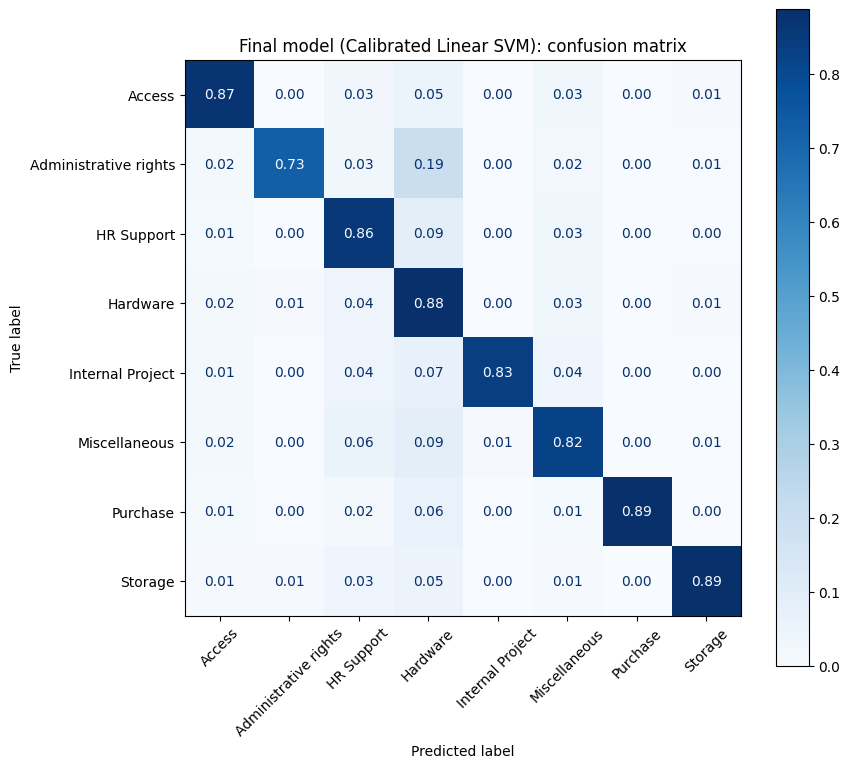

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
print("\n===== DEMO: new tickets =====")
demo = [
    "URGENT: my laptop screen is black and I cannot work, meeting in 10 minutes",
    "Please purchase two monitors for the new team, PO attached",
    "How do I increase my mailbox storage limit when possible",
    "I cannot log in, my password reset link is not working",
    "New starter joining Monday, please set up his HR profile and leave balance",
    "severity appears value highlighted picture removed analyst",   # deliberately vague
]
for t in demo:
    out = predict_ticket(t)
    print(f"\nTICKET: {t}")
    print(f"  -> {out['category']} | confidence {out['confidence']} | priority {out['priority']} "
          f"| review: {out['needs_human_review']}")
    print(f"     why: {out['priority_reason']}")

# ---------- 6) Save the confusion matrix of the FINAL model for the README ----------
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_arr, pred_cal, normalize="true", xticks_rotation=45,
    values_format=".2f", cmap="Blues", ax=ax,
)
ax.set_title("Final model (Calibrated Linear SVM): confusion matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# ---------- 7) Save and download all outputs ----------
results_df.to_csv("ticket_predictions_test.csv", index=False)
for f in ["confusion_matrix.png", "ticket_predictions_test.csv", "ticket_classifier.joblib"]:
    files.download(f)

In [19]:
import pandas as pd
from google.colab import files

# Safety check: Step 5 objects must exist
for name in ["results_df", "raw_test", "pred_cal", "URGENT", "BLOCKING", "LOW_SIGNAL",
             "HIGH_IMPACT", "first_match", "predict_ticket"]:
    assert name in globals(), f"Run Step 5 and 5b first ('{name}' is missing)."

def assign_priority(raw_text, category):
    # Return (priority, reason) from the raw ticket text and predicted category
    text = str(raw_text).lower()

    # 1) Urgent wording is always High
    hit = first_match(URGENT, text)
    if hit:
        return "High", f"urgent wording: '{hit}'"

    # 2) Blocking issue: High in high-impact categories, otherwise Medium (never Low)
    hit = first_match(BLOCKING, text)
    if hit:
        if category in HIGH_IMPACT:
            return "High", f"blocking issue ('{hit}') in high-impact category {category}"
        return "Medium", f"blocking issue ('{hit}') in lower-impact category {category}"

    # 3) Clearly non-urgent wording (only reached when nothing is blocking)
    hit = first_match(LOW_SIGNAL, text)
    if hit:
        return "Low", f"non-urgent wording: '{hit}'"

    # 4) Routine purchase requests with no urgency are Low
    if category == "Purchase":
        return "Low", "routine purchase request, no urgency or blocking signals"

    return "Medium", "no urgency or low-priority signals"

In [20]:
prio = [assign_priority(r, c) for r, c in zip(raw_test, pred_cal)]
results_df["priority"] = [p[0] for p in prio]
results_df["priority_reason"] = [p[1] for p in prio]

print("Priority distribution (%):")
print((results_df["priority"].value_counts(normalize=True) * 100).round(1))

print("\nPriority by predicted category (%):")
print((pd.crosstab(results_df["predicted_category"], results_df["priority"], normalize="index") * 100).round(1))

print("\nWhy tickets are Low:")
print(results_df.loc[results_df["priority"] == "Low", "priority_reason"].value_counts().head(8).to_string())

# ---------- Check: no Low ticket should contain a blocking phrase ----------
low = results_df[results_df["priority"] == "Low"]
bad = sum(first_match(BLOCKING, str(t).lower()) is not None for t in raw_test[results_df["priority"] == "Low"])
print("\nLow tickets containing a blocking phrase (should be 0):", bad)

print("\nRandom sample of Low tickets:")
for _, r in low.sample(min(4, len(low)), random_state=5).iterrows():
    print(f"\n[{r['predicted_category']}] {r['priority_reason']}")
    print("   ", r["ticket_text"])

# ---------- Demo again (the system uses the updated rules automatically) ----------
print("\n===== DEMO =====")
demo = [
    "URGENT: my laptop screen is black and I cannot work, meeting in 10 minutes",
    "Please purchase two monitors for the new team, PO attached",
    "How do I increase my mailbox storage limit when possible",
    "I cannot log in, my password reset link is not working",
    "Oracle error, my timecard cannot be submitted, was blocked whenever I try",
    "New starter joining Monday, please set up his HR profile and leave balance",
    "severity appears value highlighted picture removed analyst",
]
for t in demo:
    out = predict_ticket(t)
    print(f"\nTICKET: {t}")
    print(f"  -> {out['category']} | confidence {out['confidence']} | priority {out['priority']} "
          f"| review: {out['needs_human_review']}")
    print(f"     why: {out['priority_reason']}")

# ---------- Save the updated predictions ----------
results_df.to_csv("ticket_predictions_test.csv", index=False)
files.download("ticket_predictions_test.csv")

Priority distribution (%):
priority
Medium    81.1
High      13.8
Low        5.1
Name: proportion, dtype: float64

Priority by predicted category (%):
priority               High   Low  Medium
predicted_category                       
Access                 15.6   0.7    83.7
Administrative rights  27.1   1.7    71.2
HR Support              3.8   0.8    95.4
Hardware               26.0   1.0    73.0
Internal Project        9.3   0.8    89.9
Miscellaneous           5.4   0.6    93.9
Purchase                1.0  97.8     1.2
Storage                10.0   0.2    89.8

Why tickets are Low:
priority_reason
routine purchase request, no urgency or blocking signals    406
non-urgent wording: 'how can'                                24
non-urgent wording: 'wondering'                              18
non-urgent wording: 'whenever'                               12
non-urgent wording: 'suggestion'                              9
non-urgent wording: 'how should'                              6
non-urg

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>